# 24 — Showcase: multi-concept steering across 30 pairs

Broad, simple demonstration for the interim report: the 30 regime-tagged
concept pairs from Step 8 (27 unique WordNet concepts, ρ 0.19–0.57), each run
through our three composition families next to the original FRH single-concept
guidance. Not the full evaluation (that is E0–E3): one operating point
(k=4, steps=24), 10 prompts, pooled numbers.

| method | what it is |
|---|---|
| `single` | original FRH top-k CGD, one concept alone (upper reference for one concept; run once per unique concept) |
| `F1.a-mean` | frame space: steer with the chordal mean of the two concept frames |
| `F2.a-wsum` | score space: score candidates against each concept, z-score per step, sum |
| `F3.a-roundrobin` | time: one concept per step, alternating |

Success = Δexpression (metric v2, steered − unsteered baseline) per concept;
`joint` = min(Δa, Δb) — both concepts must gain. Fluency = continuation-PPL
ratio vs the unsteered greedy baseline.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.representations import FrameUnembeddingRepresentation
from frames.representations.concept import Concept
from frames.representations.schedulers import RoundRobin

In [ ]:
fur = FrameUnembeddingRepresentation.from_model_id(
    "hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4",
    device_map="cuda:0",
    torch_dtype=torch.float16,
)

MIN_LEMMAS = 11
MAX_TOKENS = 3
K = 4
STEPS = 24

PAIRS = json.loads(Path("resources/15_e0_selected_pairs.json").read_text())["all_pairs"]
SYNSETS = sorted({p[side] for p in PAIRS for side in ("a", "b")})
print(f"{len(PAIRS)} pairs over {len(SYNSETS)} unique concepts")

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

2026-07-09 22:18:17.577 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4
2026-07-09 22:18:17.580 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 5462 Mb


30 pairs over 27 unique concepts


In [3]:
def chat(user: str, assistant: str = "") -> str:
    return (
        f"<|start_header_id|>user<|end_header_id|>{user}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{assistant}"
    )


# first half of the shared E0/E1/E3 suite
PROMPTS = [
    chat("What men can be?", "1."),
    chat("What women can be?", "1."),
    chat("Tell me a short story.", "Once"),
    chat("Describe your favorite place.", "My favorite place is"),
    chat("What do you like to do on weekends?", "I like"),
    chat("Give me some advice for a good life.", "1."),
    chat(
        "What is the most important thing in the world?", "The most important thing is"
    ),
    chat("Describe the weather today.", "Today the weather is"),
    chat("What should I cook for dinner?", "You should"),
    chat("Name things that make people happy.", "1."),
]

LOG_PATH = Path("resources/24_showcase.jsonl")
LOG_PATH.unlink(missing_ok=True)

harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)
baseline_texts = harness.generate_baseline(PROMPTS, max_new_tokens=STEPS + 2)
concept = {
    name: fur.get_concept_cached(name, MIN_LEMMAS, MAX_TOKENS) for name in SYNSETS
}
print("baseline + concepts ready")

100%|██████████| 1/1 [00:02<00:00,  2.19s/it]

baseline + concepts ready


In [4]:
# original FRH guidance, once per unique concept
for name in SYNSETS:
    torch.cuda.empty_cache()
    texts, probe = fur.generate_with_topk_guide(
        PROMPTS, guide=concept[name], k=K, steps=STEPS
    )
    harness.evaluate(
        PROMPTS,
        texts,
        [name],
        config={"method": "single", "concept": name},
        probe=probe,
        baseline_texts=baseline_texts,
        concepts={name: concept[name]},
    )
    print(f"single / {name}: done")

100%|██████████| 1/1 [00:10<00:00, 10.37s/it]


single / animal.n.01: done


100%|██████████| 1/1 [00:10<00:00, 10.44s/it]


single / black.n.01: done


100%|██████████| 1/1 [00:10<00:00, 10.55s/it]


...

single / water.n.01: done


100%|██████████| 1/1 [00:11<00:00, 11.13s/it]


single / white.n.01: done


100%|██████████| 1/1 [00:11<00:00, 11.14s/it]


single / woman.n.01: done


In [5]:
def make_methods(a: Concept, b: Concept) -> dict:
    return {
        "F1.a-mean": lambda: fur.generate_with_topk_guide(
            PROMPTS, guide=Concept.average([a, b]), k=K, steps=STEPS
        ),
        "F2.a-wsum": lambda: fur.generate_with_topk_multi_guide(
            PROMPTS, guides=[a, b], k=K, steps=STEPS, normalize="zscore"
        ),
        "F3.a-roundrobin": lambda: fur.generate_with_topk_multi_guide(
            PROMPTS, guides=[a, b], k=K, steps=STEPS, scorer=RoundRobin()
        ),
    }


for pair in PAIRS:
    a, b = pair["a"], pair["b"]
    for method, generate in make_methods(concept[a], concept[b]).items():
        torch.cuda.empty_cache()
        texts, probe = generate()
        harness.evaluate(
            PROMPTS,
            texts,
            [a, b],
            config={
                "method": method,
                "a": a,
                "b": b,
                "rho": pair["rho"],
                "regime": pair["regime"],
            },
            probe=probe,
            baseline_texts=baseline_texts,
            concepts={a: concept[a], b: concept[b]},
        )
    print(f"{a} + {b} (rho={pair['rho']:.2f}): done")

100%|██████████| 1/1 [00:11<00:00, 11.15s/it]


sadness.n.01 + music.n.01 (rho=0.19): done


100%|██████████| 1/1 [00:11<00:00, 11.14s/it]


joy.n.01 + music.n.01 (rho=0.23): done


100%|██████████| 1/1 [00:11<00:00, 11.16s/it]


...

joy.n.01 + happiness.n.01 (rho=0.49): done


100%|██████████| 1/1 [00:11<00:00, 11.17s/it]


king.n.01 + queen.n.02 (rho=0.53): done


100%|██████████| 1/1 [00:11<00:00, 11.17s/it]


sorrow.n.01 + sadness.n.01 (rho=0.57): done


In [11]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
n_expected = (len(SYNSETS) + 3 * len(PAIRS)) * len(PROMPTS)
assert len(parsed) == n_expected, f"{len(parsed)} != {n_expected}"
print(f"gate: {len(parsed)} records")

rows = []
for r in parsed:
    c = r["config"]
    if c["method"] == "single":
        rows.append(
            {
                "method": "single",
                "delta_a": r["expression"][c["concept"]]["delta"],
                "delta_b": None,
                "joint": None,
                "rho": None,
                "regime": None,
                "ppl_ratio": r["ppl_ratio"],
            }
        )
    else:
        da = r["expression"][c["a"]]["delta"]
        db = r["expression"][c["b"]]["delta"]
        rows.append(
            {
                "method": c["method"],
                "delta_a": da,
                "delta_b": db,
                "joint": min(da, db),
                "rho": c["rho"],
                "regime": c["regime"],
                "ppl_ratio": r["ppl_ratio"],
            }
        )
results = pd.DataFrame(rows)

summary = (
    results.groupby("method")
    .agg(
        delta_a=("delta_a", "mean"),
        delta_b=("delta_b", "mean"),
        joint=("joint", "mean"),
        both_positive=("joint", lambda s: (s > 0).mean()),
        ppl_ratio=("ppl_ratio", "mean"),
    )
    .sort_values("joint", ascending=False)
)
summary.to_csv("resources/24_showcase_summary.csv")
summary.round(3)

gate: 1170 records


,delta_a,delta_b,joint,both_positive,ppl_ratio
method,,,,,
F1.a-mean,0.230,0.252,0.018,0.507,7.570
F3.a-roundrobin,0.182,0.201,-0.009,0.473,7.304
F2.a-wsum,0.100,0.131,-0.119,0.447,8.098
single,0.409,NaN,NaN,0.000,7.458


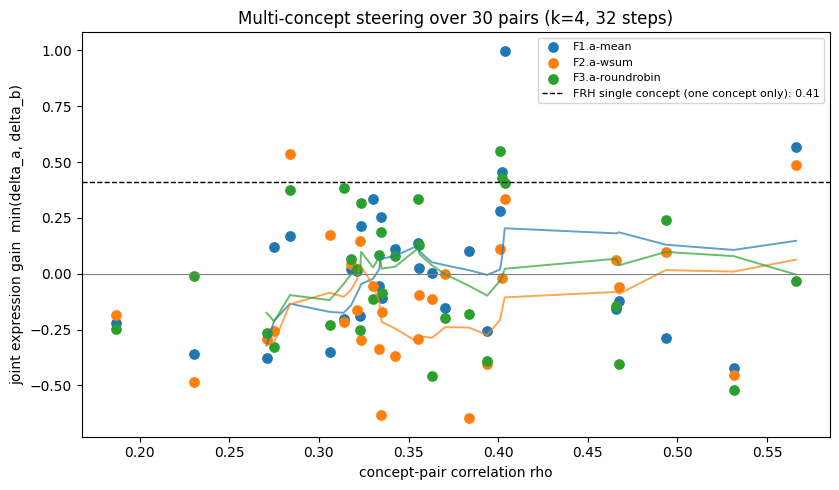

In [12]:
# joint expression vs rho, per-pair means; single-concept mean as reference
per_pair = (
    results.dropna(subset=["rho"])
    .groupby(["method", "rho", "regime"])["joint"]
    .mean()
    .reset_index()
)
single_ref = results[results["method"] == "single"]["delta_a"].mean()

colors = {
    "F1.a-mean": "tab:blue",
    "F2.a-wsum": "tab:orange",
    "F3.a-roundrobin": "tab:green",
}
fig, ax = plt.subplots(figsize=(8.5, 5))
for method, group in per_pair.groupby("method"):
    ax.scatter(group["rho"], group["joint"], s=45, color=colors[method], label=method)
    trend = group.sort_values("rho").rolling(7, on="rho", min_periods=3)["joint"].mean()
    ax.plot(
        group.sort_values("rho")["rho"], trend, color=colors[method], lw=1.4, alpha=0.7
    )
ax.axhline(0, color="gray", lw=0.8)
ax.axhline(
    single_ref,
    color="black",
    ls="--",
    lw=1,
    label=f"FRH single concept (one concept only): {single_ref:.2f}",
)
ax.set_xlabel("concept-pair correlation rho")
ax.set_ylabel("joint expression gain  min(delta_a, delta_b)")
ax.set_title(f"Multi-concept steering over {len(PAIRS)} pairs (k={K}, {STEPS} steps)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("resources/24_showcase_joint_vs_rho.png", dpi=150)
plt.show()

In [13]:
per_regime = (
    results.dropna(subset=["rho"])
    .groupby(["regime", "method"])
    .agg(joint=("joint", "mean"), both_positive=("joint", lambda s: (s > 0).mean()))
    .round(3)
)
print(per_regime.to_string())

                               joint  both_positive
regime        method                               
antonym       F1.a-mean       -0.026          0.500
              F2.a-wsum       -0.159          0.467
              F3.a-roundrobin  0.036          0.583
compositional F1.a-mean        0.123          0.567
              F2.a-wsum       -0.057          0.600
              F3.a-roundrobin -0.008          0.367
hypernym      F1.a-mean        0.053          0.457
              F2.a-wsum       -0.075          0.443
              F3.a-roundrobin -0.065          0.386
related       F1.a-mean       -0.201          0.400
              F2.a-wsum       -0.215          0.300
              F3.a-roundrobin  0.383          0.600
similar       F1.a-mean        0.120          0.540
              F2.a-wsum        0.011          0.460
              F3.a-roundrobin -0.060          0.420
unrelated     F1.a-mean       -0.056          0.525
              F2.a-wsum       -0.219          0.388
            

In [17]:
def answer(text: str) -> str:
    return text.split("assistant<|end_header_id|>")[-1].strip()


SHOW_PAIR = ("sadness.n.01", "music.n.01")
for r in parsed:
    c = r["config"]
    if "short story" not in r["prompt"]:
        continue
    if (c.get("a"), c.get("b")) == SHOW_PAIR or c.get("concept") in SHOW_PAIR:
        deltas = {
            k.split(".")[0]: round(v["delta"], 2) for k, v in r["expression"].items()
        }
        print(f"[{c['method']}] {deltas}")
        print("   ", answer(r["text"])[:150], "\n")

[single] {'music': -0.12}
    Once, in an old antique clockwork shop in Paris' winding streets of the Le Louvre quarter. A small wooden case, 

[single] {'sadness': 0.12}
    Once, on Moon Island (a small specks in an ocean far away) there existed an eccentric inventor. The man spent most 

[F1.a-mean] {'sadness': 0.17, 'music': 0.09}
    Once, a long-finger pianoforté was left behind by its family in an antique shop. For years, the shop 

[F2.a-wsum] {'sadness': 0.0, 'music': 0.31}
    Once, in an old antique clockmaker's shop in Paris's charming Le Quartiers Latin quarter, an old, intricate pocket watch 

[F3.a-roundrobin] {'sadness': -0.01, 'music': 0.09}
    Once, in an old antique clockmaker's shop in Paris' charming Le Louvre quarter. A small, exquisite music-box sat 

